# Marine heatwave projections

Marine-heatwave (MHW) days per year (all categories, Hobday et al. 2018) from the CMIP6 MHW statistics of Holbrook et al. for SSP1-2.6 and SSP5-8.5, averaged over each Pacific EEZ and ocean region on every model's native ocean grid. The model domain ends at 15°N, so EEZs and regions further north are only partly covered (or not at all: hatched EEZs).

```{glue:figure} mhw_fig
:scale: 60%
:align: center
```

**Figure. MHW days per year in each Pacific EEZ at the global warming levels** (multi-model median, SSP5-8.5).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and ocean-region means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels use `map_scenario`; box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp585']
map_scenario = "ssp585"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## MHW days per year

Values are the MHW days themselves (not a change), because the historical baseline is close to zero days per year.

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,North Pacific Subtropical Gyre,SSP126,+1.5°C,2032,18,201.9,92.4,270.2,34.0,293.1
1,North Pacific Subtropical Gyre,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,North Pacific Subtropical Gyre,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,North Pacific Subtropical Gyre,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,North Pacific Subtropical Gyre,SSP585,+1.5°C,2027,18,155.9,104.6,222.0,32.9,302.2
5,North Pacific Subtropical Gyre,SSP585,+2.0°C,2041,18,302.4,220.9,352.9,156.7,356.7
6,North Pacific Subtropical Gyre,SSP585,+2.5°C,2053,18,341.1,273.6,358.0,171.5,365.0
7,North Pacific Subtropical Gyre,SSP585,+3.0°C,2064,18,361.7,341.5,365.7,102.3,366.0
8,Equatorial Upwelling,SSP126,+1.5°C,2032,18,136.7,38.2,248.1,0.0,258.9
9,Equatorial Upwelling,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN


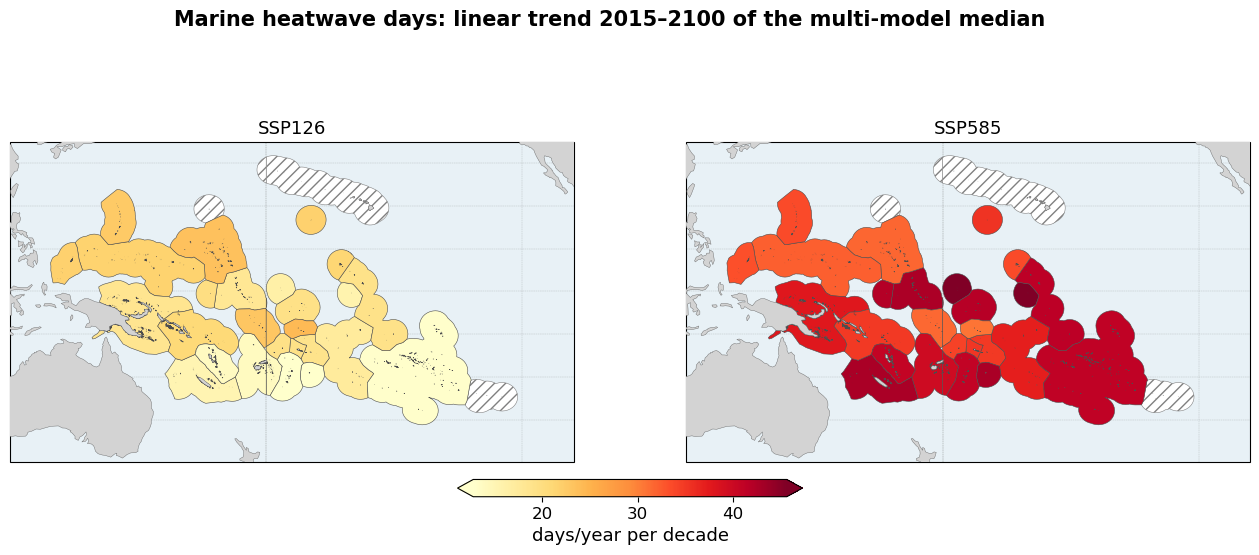

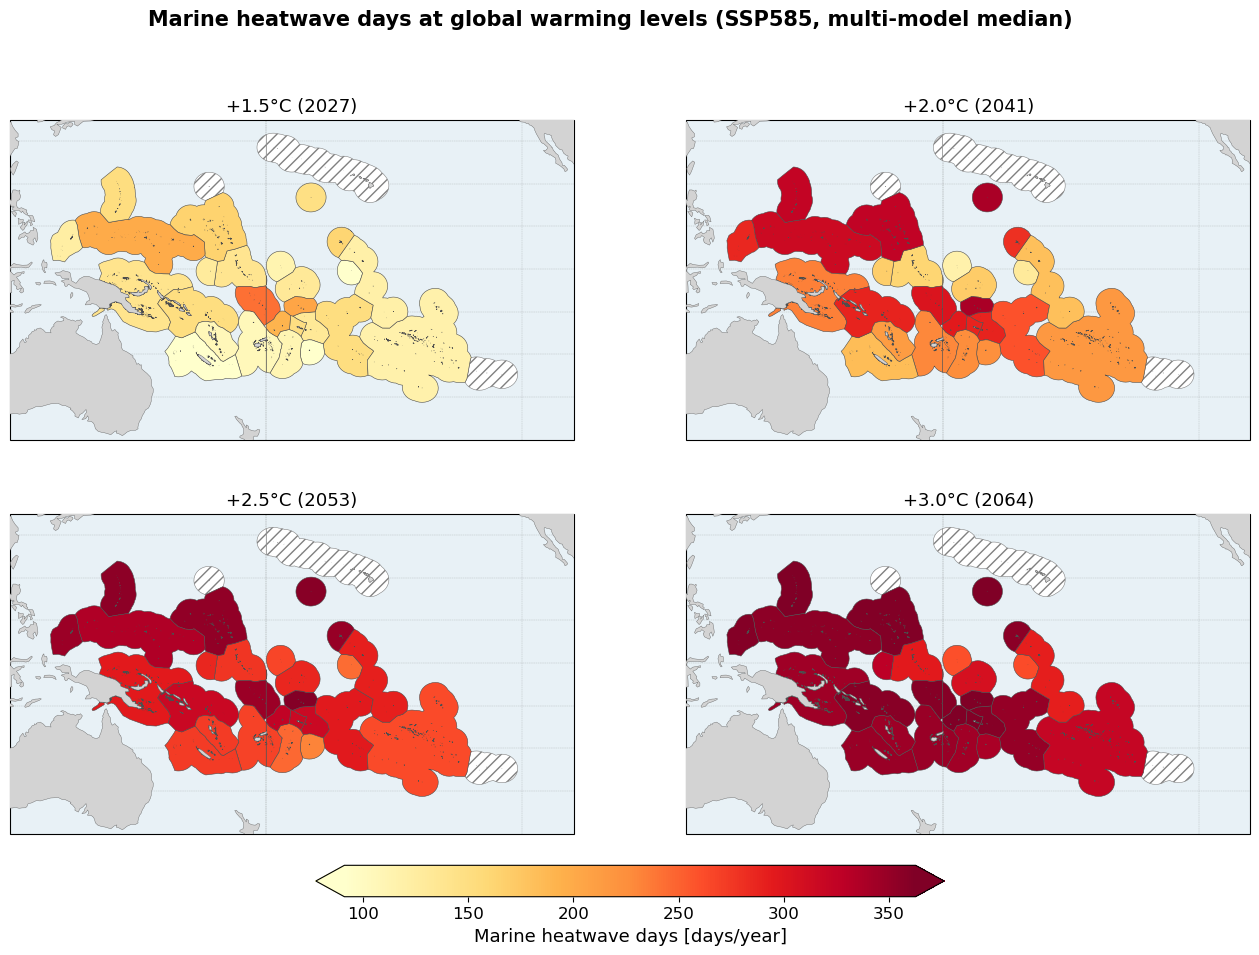

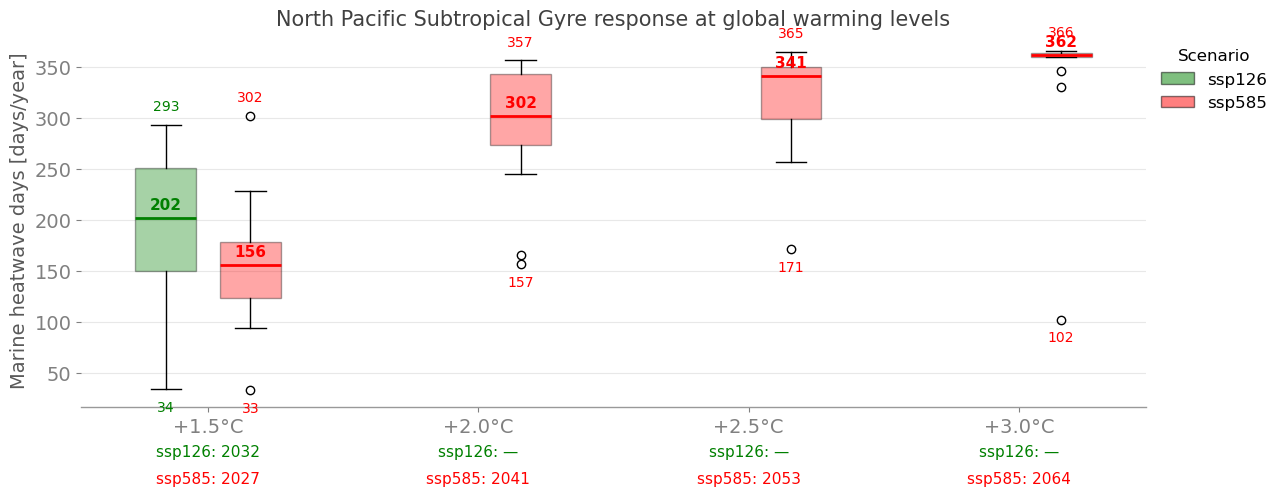

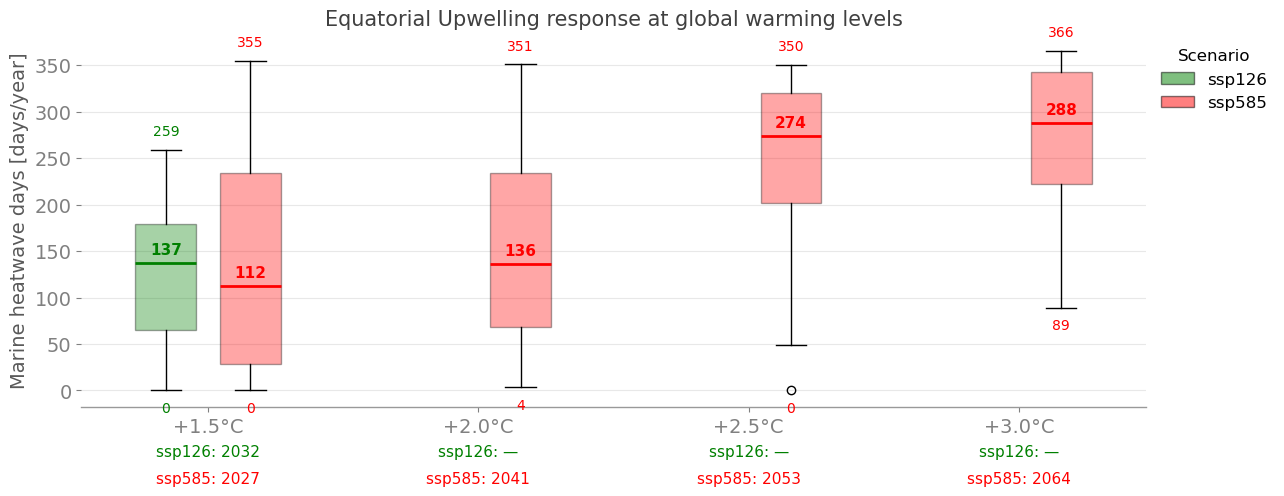

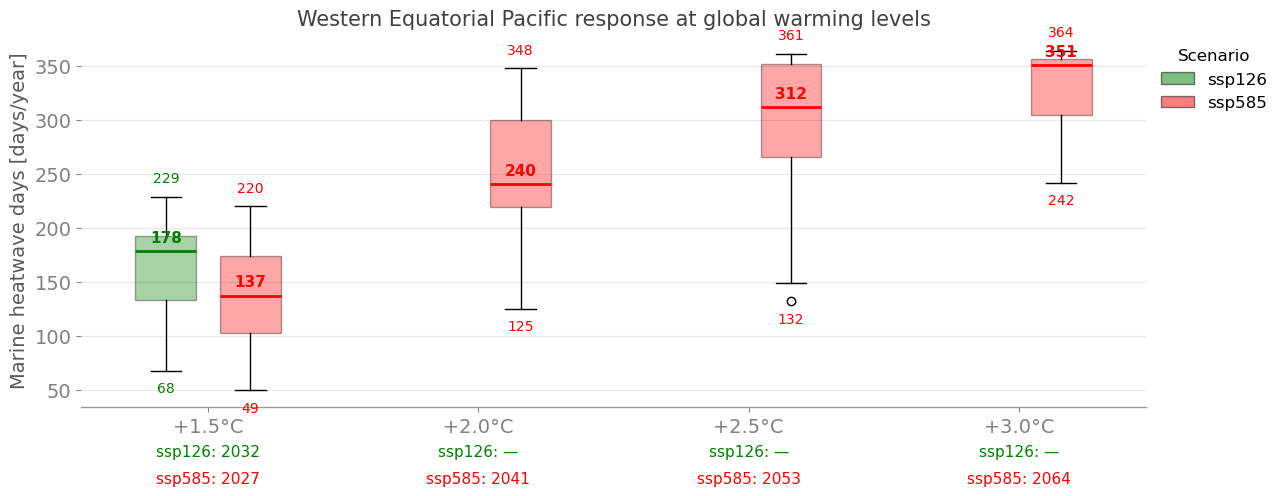

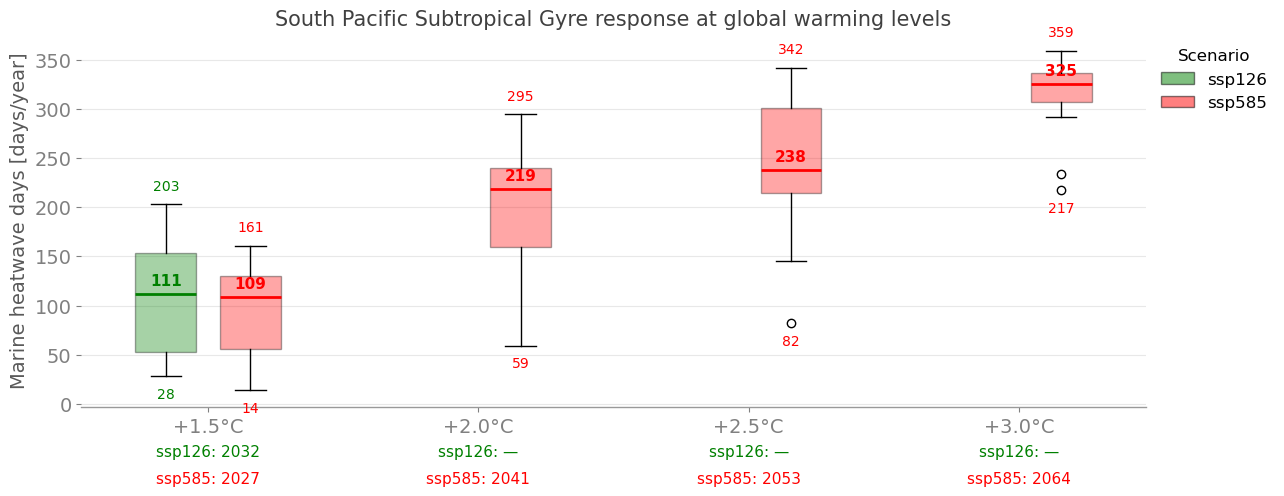

In [4]:
ds_mhw = reg.extract_mhw_regional(eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds_mhw, "mhw_days", scenario_info, eez, ssp_scenarios, map_scenario,
                                    fig_dir, tables_dir, absolute=True)
glue("mhw_fig", figs["levels"], display=False)
tables["regions"]